**ФИО студента:** [ФИО]

**Задание:** [`outpainting`]

**Группа:** [номер группы]

**Дата сдачи:** [23.11.26]

## Блок настройки окружения

Код для импорта библиотек, для формирования глобальных констант, других конфигураций (если требуется). Постарайтесь здесь зафиксировать все seed, которые сможете

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

from pathlib import Path

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Окружение настроено успешно")

NumPy: 2.2.6
Окружение настроено успешно


## Блок "Данные"

Код и информация о том, как были подготовлены данные для обучения модели

> Загружаем данные без полного копирования массива в RAM:

In [2]:
DATA_PATH = Path(
    "input_seismic_data/outpainting_cube_missed_data.npy"
)

cube = np.load(DATA_PATH, mmap_mode="r")

print("Shape:", cube.shape)
print("Dtype:", cube.dtype)
print("Размер (МБ):", round(cube.nbytes / 1024**2, 2))

assert cube.shape == (460, 481, 800)

Shape: (460, 481, 800)
Dtype: float32
Размер (МБ): 675.23


> Исследуем три среза по второй оси:


Левый край
Min: 0.0
Max: 0.0
NaN (%): 0.0
Zeros (%): 100.0

Центр
Min: 0.18832973
Max: 0.94665366
NaN (%): 0.0
Zeros (%): 0.0

Правый край
Min: 0.0
Max: 0.0
NaN (%): 0.0
Zeros (%): 100.0


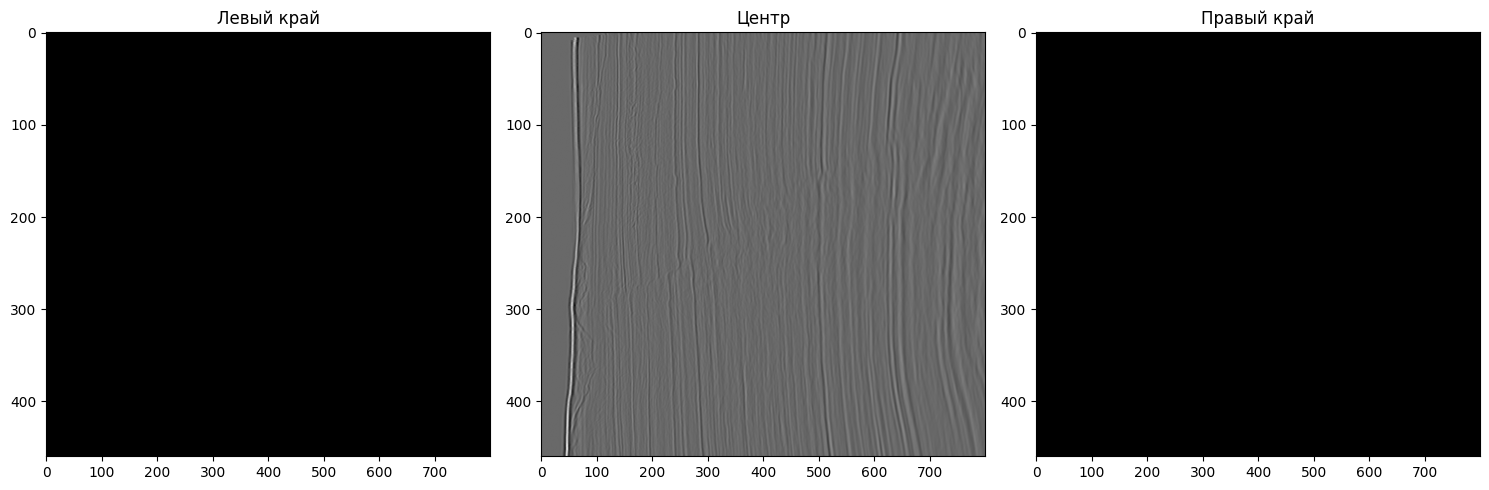

In [3]:
slices = {
    "Левый край": cube[:, 0, :],
    "Центр": cube[:, 240, :],
    "Правый край": cube[:, 480, :]
}

for name, data in slices.items():
    print(f"\n{name}")
    print("Min:", np.nanmin(data))
    print("Max:", np.nanmax(data))
    print("NaN (%):", np.isnan(data).mean() * 100)
    print("Zeros (%):", (data == 0).mean() * 100)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, data) in zip(axes, slices.items()):
    ax.imshow(data, cmap="gray", aspect="auto")
    ax.set_title(name)

plt.tight_layout()
plt.show()

> Для наглядности решил также проверить границы диапозонов, там где данные есть и где уже нет с шагом в одну позицию:

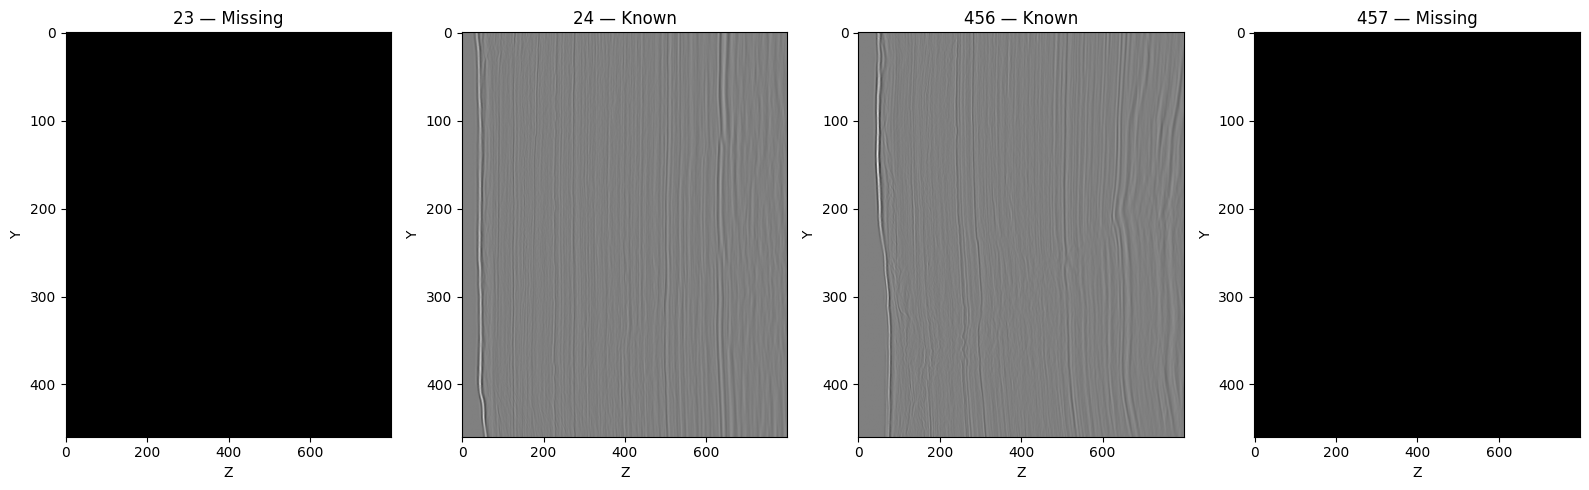

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

indices = [23, 24, 456, 457]
titles = [
    "23 — Missing",
    "24 — Known",
    "456 — Known",
    "457 — Missing"
]

for ax, i, title in zip(axes, indices, titles):
    ax.imshow(
        cube[:, i, :],
        cmap="gray",
        vmin=0,
        vmax=1,
        aspect="auto"
    )
    ax.set_title(title)
    ax.set_xlabel("Z")
    ax.set_ylabel("Y")

plt.tight_layout()
plt.show()


> Создадим искусственные пропуски в данных - берём полностью известный фрагмент сейсмического куба, сохраняем его оригинал, а затем заменяем 24 позиции по краям нулями. Нейросеть будет сравнивать свой результат с правильным ответом и постепенно обучаться восстанавливать скрытые значения.

Размер фрагмента: (128, 256)


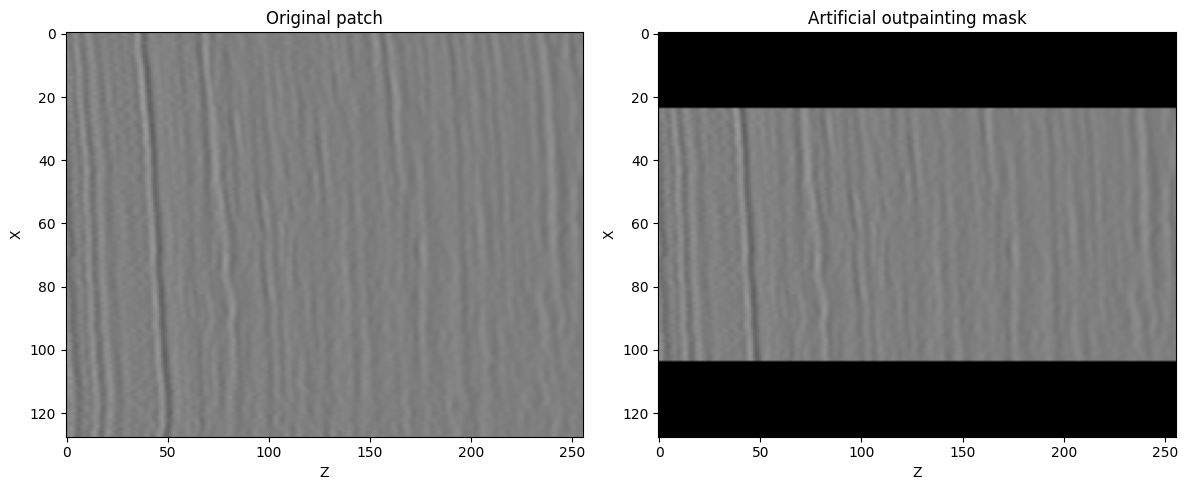

In [5]:
# Выбираем полностью известный фрагмент куба
patch = np.array(
    cube[150, 160:288, 240:496],
    copy=True
)

print("Размер фрагмента:", patch.shape)

# Создаём копию с искусственными пропусками
masked_patch = patch.copy()

# Скрываем по 24 позиции с обеих сторон
masked_patch[:24, :] = 0
masked_patch[-24:, :] = 0

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    patch,
    cmap="gray",
    vmin=0,
    vmax=1,
    aspect="auto"
)
axes[0].set_title("Original patch")

axes[1].imshow(
    masked_patch,
    cmap="gray",
    vmin=0,
    vmax=1,
    aspect="auto"
)
axes[1].set_title("Artificial outpainting mask")

for ax in axes:
    ax.set_xlabel("Z")
    ax.set_ylabel("X")

plt.tight_layout()
plt.show()

> Далее разделим данные на три выборки - **train** / **vadation** / **test**, просто случайно перемешать все фрагменты и распределить их по выборкам не самая лучшая идея так как модель может получить практически одинаковые структуры в train и test, что приведёт к завышенной оценке качества, поэтому мы разделим куб на непересекающиеся области вдоль первой оси (Y):

In [8]:
# Разделение вдоль первой оси Y
splits = {
    "train": (0, 300),
    "val": (320, 380),
    "test": (400, 460)
}

for name, (start, end) in splits.items():
    print(f"{name}: Y = [{start}, {end}), "
          f"количество срезов = {end - start}")

# Проверяем отсутствие пересечений
assert splits["train"][1] < splits["val"][0]
assert splits["val"][1] < splits["test"][0]

print("\nРазделение выполнено успешно.")

train: Y = [0, 300), количество срезов = 300
val: Y = [320, 380), количество срезов = 60
test: Y = [400, 460), количество срезов = 60

Разделение выполнено успешно.


> При обучении будем случайным образом брать известный фрагмент и скрывать 24 позиции с одной стороны.
> Реализуем функцию, которая создаёт один такой пример:

In [9]:
PATCH_X = 128
PATCH_Z = 256
MISSING_WIDTH = 24

rng = np.random.default_rng(SEED)

def create_sample(split="train", side="left"):
    # 1. Выбираем случайную позицию Y из нужной выборки
    y_min, y_max = splits[split]
    y = rng.integers(y_min, y_max)

    # 2. Выбираем случайный фрагмент из известной области
    x_start = rng.integers(24, 457 - PATCH_X + 1)
    z_start = rng.integers(0, 800 - PATCH_Z + 1)

    # 3. Получаем оригинальный фрагмент
    target = np.array(
        cube[
            y,
            x_start:x_start + PATCH_X,
            z_start:z_start + PATCH_Z
        ],
        copy=True
    )

    # 4. Создаём вход для нейросети
    input_patch = target.copy()

    if side == "left":
        input_patch[:MISSING_WIDTH, :] = 0
    elif side == "right":
        input_patch[-MISSING_WIDTH:, :] = 0
    else:
        raise ValueError("side должен быть left или right")

    return input_patch, target

> Построим два примера - с левым и правым искусственными пропусками:

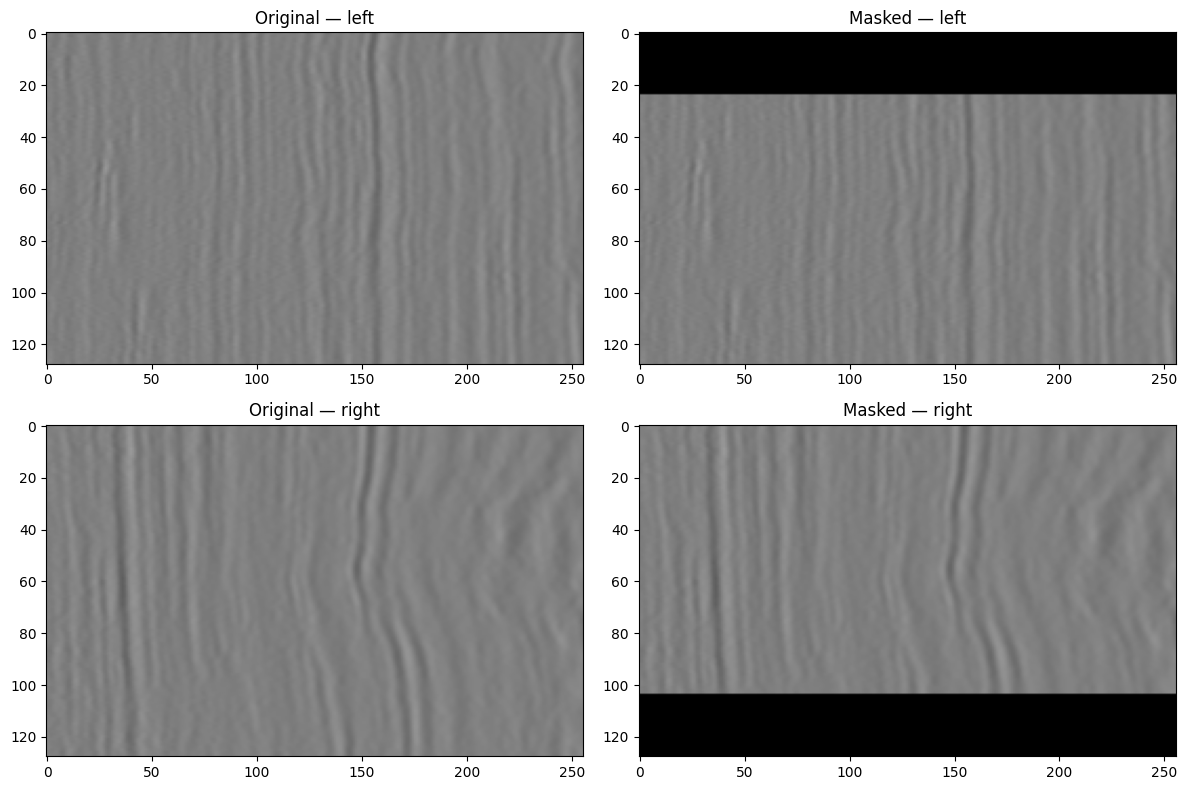

Размер входа: (128, 256)
Размер ответа: (128, 256)
Доля скрытых значений: 18.75 %


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, side in enumerate(["left", "right"]):

    input_patch, target = create_sample(
        split="train",
        side=side
    )

    axes[row, 0].imshow(
        target,
        cmap="gray",
        vmin=0,
        vmax=1,
        aspect="auto"
    )
    axes[row, 0].set_title(f"Original — {side}")

    axes[row, 1].imshow(
        input_patch,
        cmap="gray",
        vmin=0,
        vmax=1,
        aspect="auto"
    )
    axes[row, 1].set_title(f"Masked — {side}")

plt.tight_layout()
plt.show()

print("Размер входа:", input_patch.shape)
print("Размер ответа:", target.shape)
print("Доля скрытых значений:",
      round(np.mean(input_patch == 0) * 100, 2), "%")

## Блок "Модель"

Код и информация о том, какая модель была использована

In [ ]:
...

## Блок "Обучение модели"

Код и информация о том, как был выстроен пайплайн обучения модели (optimizer/scheduler, loss, metrics, training loop, etc). Графики обучения (train + val) по loss + metrics

In [ ]:
...

## Блок "Тестирование модели"

Код и информация о том, как выглядят результаты предсказания на тестовой выборке

In [ ]:
...

## Блок "Инференса модели"

Код и информация о том, как "затягиваются" пропущенные данные в кубе

In [ ]:
...

## Блок сохранения артефактов

Код и информация о том, как сохранялась модель и восстановленный куб (shape финального куба должен совпадать с shape'ом входного куба, который был скачан по ссылке)

In [ ]:
...